# Planejamento do Projeto — Planejamento da Cadeia de Suprimentos

## Objetivo do Projeto

Analisar e otimizar a cadeia de suprimentos de uma empresa de distribuição industrial, identificando ineficiências operacionais e propondo estratégias baseadas em dados para reduzir rupturas de estoque, melhorar o nível de serviço dos fornecedores e diminuir custos logísticos.

O projeto cobre o ciclo completo de um projeto de Ciência de Dados aplicado a Supply Chain: da exploração dos dados até a construção de modelos preditivos e geração de recomendações acionáveis para o negócio.

---

## Contexto de Negócio

A empresa distribui materiais industriais (ferramentas, EPIs, fixadores, materiais elétricos e de manutenção) para clientes em todo o Brasil. Ela trabalha com fornecedores nacionais e internacionais, com prazos de entrega acordados que variam de 3 a 45 dias.

**Principais dores identificadas:**
- Rupturas de estoque em produtos de alto giro durante períodos de pico
- Atrasos frequentes de fornecedores internacionais que comprometem o abastecimento
- Custo logístico elevado sem visibilidade clara dos principais drivers
- Ausência de previsão de demanda estruturada — compras baseadas em experiência empírica


# Etapa 1 — Análise Exploratória de Dados (EDA)

**Projeto:** Planejamento da Cadeia de Suprimentos  
**Objetivo:** Entender a base de dados, identificar padrões operacionais e levantar hipóteses de negócio que guiarão as etapas seguintes do projeto.

---

## 1. Importação de Bibliotecas e Carregamento dos Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

In [2]:
# Carregar base principal e tabelas de referência
df = pd.read_csv('data/base_cadeia_suprimentos.csv')
ref_produtos    = pd.read_csv('data/ref_produtos.csv')
ref_fornecedores = pd.read_csv('data/ref_fornecedores.csv')
ref_regioes     = pd.read_csv('data/ref_regioes.csv')

# Converter datas
df['data_pedido']          = pd.to_datetime(df['data_pedido'])
df['data_entrega_prevista'] = pd.to_datetime(df['data_entrega_prevista'])
df['data_entrega_real']    = pd.to_datetime(df['data_entrega_real'])

print(f'Base principal: {df.shape[0]:,} registros | {df.shape[1]} colunas')
df.head(3)

Base principal: 4,406 registros | 31 colunas


,id_pedido,data_pedido,ano,mes,trimestre,id_produto,produto,categoria,giro_produto,id_fornecedor,...,status_entrega,estoque_disponivel,estoque_minimo,estoque_maximo,ruptura_estoque,custo_frete,custo_armazenagem,prazo_pagamento_dias,regiao_destino,estado_destino
0,PED000001,2022-01-03,2022,1,1,P07,Capacete de Seguranca,EPI,alto,F04,...,No Prazo,759,600,2000,0,62.87,31.10,25,Sudeste,SP
1,PED000002,2022-01-03,2022,1,1,P07,Capacete de Seguranca,EPI,alto,F09,...,No Prazo,923,600,2000,0,182.51,53.11,60,Nordeste,BA
2,PED000003,2022-01-04,2022,1,1,P08,Cabo Flexivel,Eletroeletronicos,alto,F04,...,No Prazo,1222,360,1200,0,28.15,12.64,30,Sudeste,SP


In [3]:

df['ruptura_real'] = (df['quantidade_pedida'] > df['estoque_disponivel']).astype(int)

print(df['ruptura_real'].value_counts())
print(f"Percentage of ruptures: {df['ruptura_real'].mean() * 100:.2f}%")

ruptura_real
0    4336
1      70
Name: count, dtype: int64
Percentage of ruptures: 1.59%


## 2. Visão Geral da Base

In [4]:
print('=== TIPOS E NULOS ===')
info = pd.DataFrame({
    'dtype':  df.dtypes,
    'nulos':  df.isnull().sum(),
    '% nulo': (df.isnull().mean() * 100).round(2)
})
display(info)

print('\n=== ESTATÍSTICAS DESCRITIVAS (numéricas) ===')
display(df.describe().round(2))

=== TIPOS E NULOS ===


,dtype,nulos,% nulo
id_pedido,str,0,0.0
data_pedido,datetime64[us],0,0.0
ano,int64,0,0.0
mes,int64,0,0.0
trimestre,int64,0,0.0
id_produto,str,0,0.0
produto,str,0,0.0
categoria,str,0,0.0
giro_produto,str,0,0.0
id_fornecedor,str,0,0.0



=== ESTATÍSTICAS DESCRITIVAS (numéricas) ===


,data_pedido,ano,mes,trimestre,confiabilidade_forn,quantidade_pedida,preco_unitario,valor_total_pedido,prazo_entrega_acordado_dias,data_entrega_prevista,data_entrega_real,atraso_dias,estoque_disponivel,estoque_minimo,estoque_maximo,ruptura_estoque,custo_frete,custo_armazenagem,prazo_pagamento_dias,ruptura_real
count,4406,4406.00,4406.00,4406.00,4406.00,4406.00,4406.00,4406.00,4406.00,4406,4406,4406.00,4406.00,4406.00,4406.00,4406.00,4406.00,4406.00,4406.00,4406.00
mean,2023-07-09 20:15:47.798456,2023.02,6.52,2.51,0.88,769.15,25.24,4121.36,11.84,2023-07-21 16:27:59.891057,2023-07-21 20:20:02.723558,0.16,97392.55,1687.71,5625.69,0.04,102.50,57.63,35.69,0.02
min,2022-01-03 00:00:00,2022.00,1.00,1.00,0.75,1.00,0.87,19.77,3.00,2022-01-06 00:00:00,2022-01-06 00:00:00,-2.00,17.00,60.00,200.00,0.00,16.19,0.22,25.00,0.00
25%,2022-10-04 00:00:00,2022.00,4.00,2.00,0.85,63.00,4.47,904.40,4.00,2022-10-15 00:00:00,2022-10-15 06:00:00,0.00,3457.25,120.00,400.00,0.00,49.38,12.27,30.00,0.00
50%,2023-07-14 00:00:00,2023.00,7.00,3.00,0.88,205.00,12.89,2485.77,6.00,2023-07-26 00:00:00,2023-07-26 00:00:00,0.00,19041.00,600.00,2000.00,0.00,69.06,33.30,30.00,0.00
75%,2024-04-10 00:00:00,2024.00,9.00,3.00,0.92,479.00,22.08,5315.14,15.00,2024-04-22 18:00:00,2024-04-22 18:00:00,0.00,59616.25,600.00,2000.00,0.00,107.89,73.57,45.00,0.00
max,2024-12-31 00:00:00,2024.00,12.00,4.00,0.93,4993.00,606.68,28617.50,45.00,2025-02-13 00:00:00,2025-02-13 00:00:00,11.00,728263.00,6000.00,20000.00,1.00,986.89,522.63,60.00,1.00
std,NaN,0.82,3.26,1.08,0.04,1262.10,65.79,4730.42,11.99,NaN,NaN,1.89,177603.59,2397.20,7990.67,0.19,108.89,69.52,9.11,0.13


In [5]:
# Período coberto
print(f"Período: {df['data_pedido'].min().date()} a {df['data_pedido'].max().date()}")
print(f"Anos:    {sorted(df['ano'].unique())}")
print(f"Produtos únicos:    {df['id_produto'].nunique()}")
print(f"Fornecedores únicos: {df['id_fornecedor'].nunique()}")
print(f"Estados de destino:  {df['estado_destino'].nunique()}")
print(f"Categorias:  {df['categoria'].nunique()}")

Período: 2022-01-03 a 2024-12-31
Anos:    [np.int64(2022), np.int64(2023), np.int64(2024)]
Produtos únicos:    20
Fornecedores únicos: 10
Estados de destino:  13
Categorias:  6


## Metadados do Dataset

| Atributo              | Valor                        |
|-----------------------|------------------------------|
| **Período coberto**   | 03/01/2022 a 31/12/2024      |
| **Anos disponíveis**  | 2022, 2023, 2024             |
| **Produtos únicos**   | 20                           |
| **Fornecedores únicos** | 10                         |
| **Estados de destino** | 13                          |
| **Categorias**        | 6                            |

## 3. Distribuição dos Pedidos

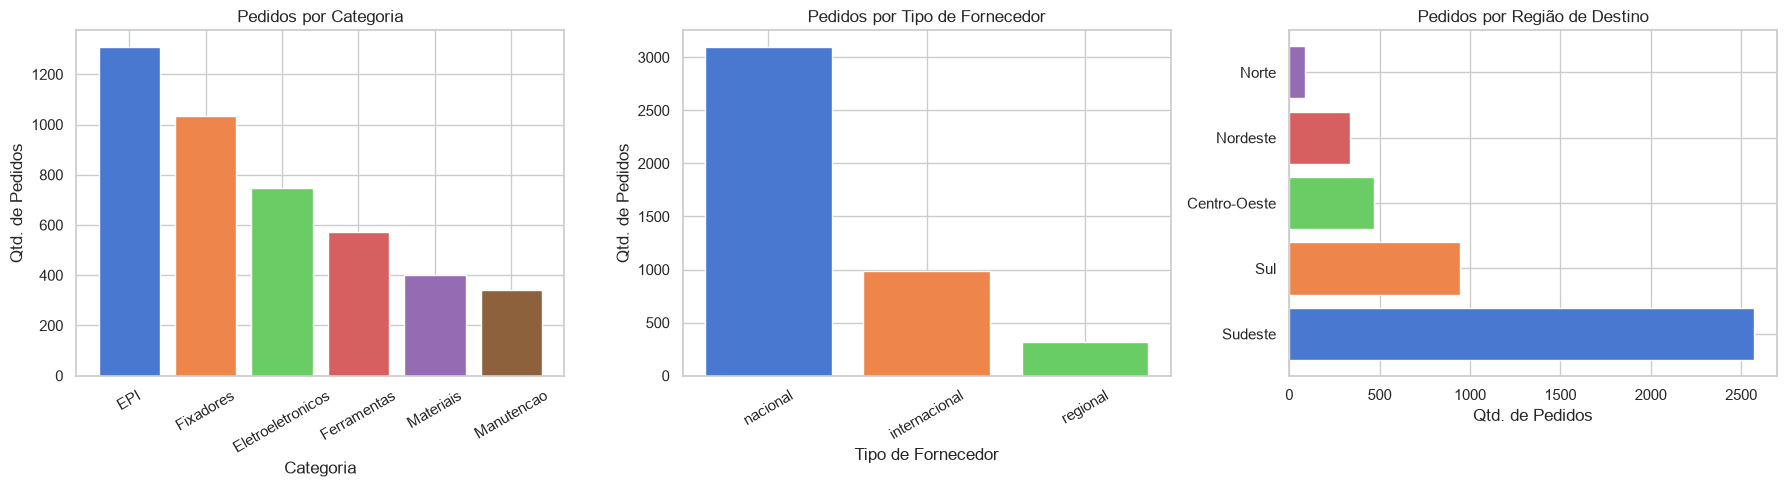

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Por categoria
cat_counts = df['categoria'].value_counts()
axes[0].bar(cat_counts.index, cat_counts.values, color=sns.color_palette('muted', len(cat_counts)))
axes[0].set_title('Pedidos por Categoria')
axes[0].set_xlabel('Categoria')
axes[0].set_ylabel('Qtd. de Pedidos')
axes[0].tick_params(axis='x', rotation=30)

# Por tipo de fornecedor
tipo_counts = df['tipo_fornecedor'].value_counts()
axes[1].bar(tipo_counts.index, tipo_counts.values, color=sns.color_palette('muted', len(tipo_counts)))
axes[1].set_title('Pedidos por Tipo de Fornecedor')
axes[1].set_xlabel('Tipo de Fornecedor')
axes[1].set_ylabel('Qtd. de Pedidos')
axes[1].tick_params(axis='x', rotation=30)

# Por região de destino
reg_counts = df['regiao_destino'].value_counts()
axes[2].barh(reg_counts.index, reg_counts.values, color=sns.color_palette('muted', len(reg_counts)))
axes[2].set_title('Pedidos por Região de Destino')
axes[2].set_xlabel('Qtd. de Pedidos')

plt.tight_layout()
plt.show()

#### Pedidos por categoria:
→ EPI (29,7%) e Fixadores (23,5%) concentram mais da metade dos pedidos (53,2%) e devem ter gestão prioritária de estoque e fornecedores dedicados.

#### Pedidos por tipo de Fornecedor:
→ 70,3% dos pedidos vêm de fornecedores nacionais, 22,4% de internacionais e apenas 7,3% do fornecedor regional. A concentração em nacionais reduz lead time, mas aumenta a vulnerabilidade a choques locais; o fornecimento regional segue subutilizado.

#### Pedidos por Região de Destino:
→ Sudeste (58,3%) e Sul (21,5%) juntos representam ~80% do volume. O Centro-Oeste é a terceira região (10,6%), à frente do Nordeste (7,6%) e do Norte (1,9%). Estrutura logística e estoques devem ser dimensionados com foco em Sudeste e Sul.

### Conclusão:
A operação apresenta três padrões de concentração: nos produtos (EPI e Fixadores), nos fornecedores (nacionais) e na distribuição geográfica (Sudeste). Essa estrutura é eficiente no curto prazo, mas eleva o risco operacional. A prioridade estratégica deve ser diversificar a base de fornecedores regionais e avaliar se a baixa penetração em Norte e Nordeste (menos de 10% dos pedidos somados) é uma lacuna de mercado ou uma limitação logística.

## 4. Análise Temporal — Sazonalidade da Demanda

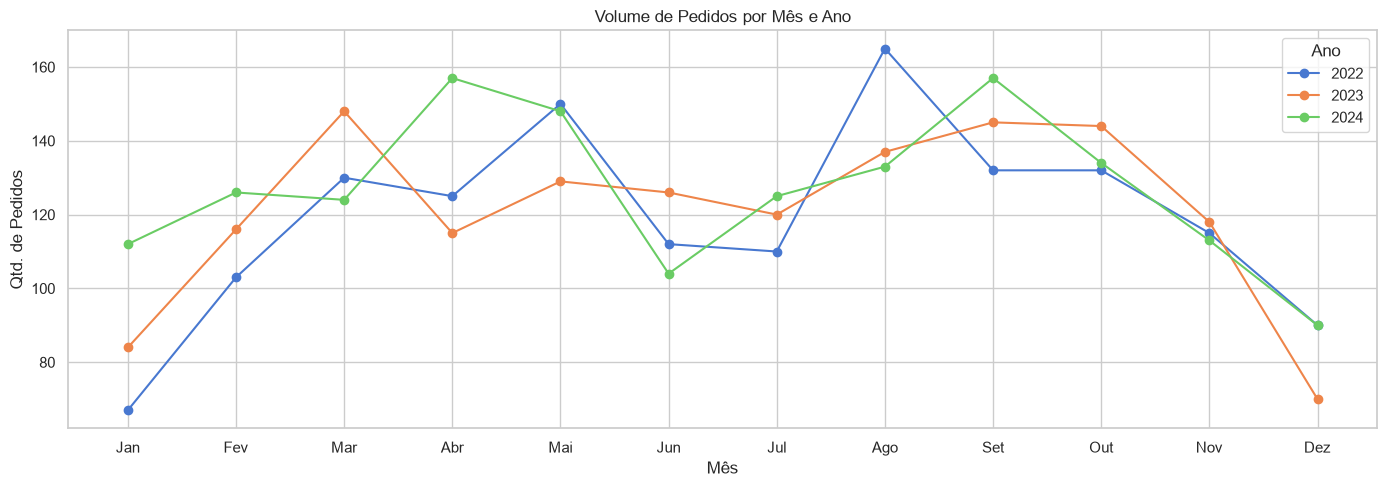

In [7]:
# Volume de pedidos por mês/ano
pedidos_mes = df.groupby(['ano', 'mes']).size().reset_index(name='qtd_pedidos')
pedidos_mes['periodo'] = pd.to_datetime(pedidos_mes[['ano','mes']].assign(day=1).rename(columns={'ano': 'year', 'mes': 'month'}))

fig, ax = plt.subplots(figsize=(14, 5))
for ano, grupo in pedidos_mes.groupby('ano'):
    ax.plot(grupo['mes'], grupo['qtd_pedidos'], marker='o', label=str(ano))
ax.set_title('Volume de Pedidos por Mês e Ano')
ax.set_xlabel('Mês')
ax.set_ylabel('Qtd. de Pedidos')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez'])
ax.legend(title='Ano')
plt.tight_layout()
plt.show()

## Análise: Volume de Pedidos por Mês e Ano

### Visão Geral
O gráfico apresenta a quantidade de pedidos mensais ao longo de três anos (2022, 2023 e 2024),
permitindo comparação sazonal e tendência interanual.

---

### Observações por Ano

**2022 (azul)**
- Início fraco em Janeiro (67) — o mês mais baixo do ano — com forte recuperação em Fevereiro (103) e Março (130).
- Pico do ano em Agosto (165), após uma leve retração em Junho e Julho (112 e 110).
- Queda constante a partir de Setembro, encerrando em Dezembro (90), o segundo mês mais fraco do ano.

**2023 (laranja)**
- Início também fraco (Janeiro, 84), com recuperação gradual até o pico do ano em Março (148).
- Patamar elevado e relativamente estável entre Agosto e Outubro (137–145).
- Dezembro despenca para 70 pedidos — o mês mais fraco do ano e o segundo mais fraco de toda a série
  (atrás apenas de Janeiro/2022, com 67).

**2024 (verde)**
- Ano de maior volume total — Janeiro já começa mais forte que nos anos anteriores (112).
- Dois picos no ano, praticamente empatados: Abril e Setembro, ambos com 157 pedidos.
- Queda pontual em Junho (104) entre os dois picos, e fechamento novamente baixo em Dezembro (90).

---

### Padrões Sazonais Identificados

| Período      | Comportamento recorrente                                              |
|--------------|-------------------------------------------------------------------------|
| Dezembro     | Mês mais fraco em 2023 e 2024 e o segundo mais fraco em 2022 (70–90 pedidos) — vale sazonal de fim de ano |
| Janeiro      | Também abaixo da média nos três anos, mas crescendo ano a ano (67→84→112) |
| Fev–Mar      | Recuperação consistente após o início do ano                            |
| Picos do ano | Variam de ano para ano: Agosto (2022), Março (2023), Abril e Setembro (2024) |
| Junho        | Retração frente a Maio nos três anos, mais forte em 2022 e 2024         |

---

### Conclusões

- **Dezembro e Janeiro formam o vale sazonal da série**: Dezembro é o mês mais fraco em 2023 e 2024
  (70 e 90 pedidos) e Janeiro o mais fraco em 2022 (67) — início e fim de ano concentram sempre
  os menores volumes.
- **Janeiro também é sistematicamente fraco**, mas evolui claramente ano a ano (67 → 84 → 112),
  sugerindo expansão real da base de clientes ou do mercado, e não apenas sazonalidade.
- **O volume total cresce de forma constante ano a ano**: 1.431 pedidos em 2022, 1.452 em 2023
  e 1.523 em 2024 — crescimento contínuo, sem retração intermediária.
- **2022 apresenta a maior amplitude entre pico e vale** (98 pedidos, entre Janeiro e Agosto),
  indicando maior volatilidade mensal naquele ano; a amplitude cai para 78 em 2023 e 67 em 2024,
  sugerindo uma demanda progressivamente mais estável.


## Demanda Total (Qtd.) por Mês e Categoria

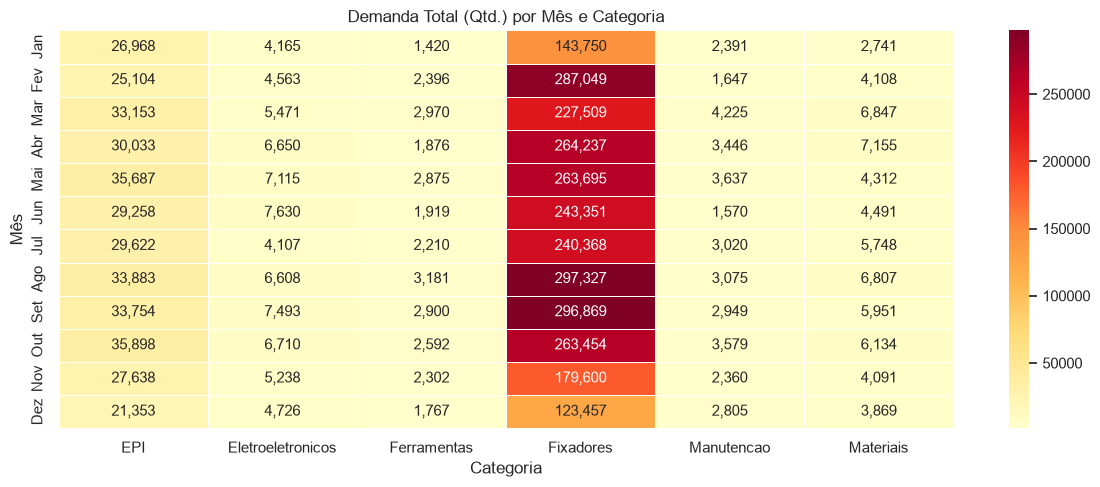

In [8]:
# Demanda por categoria ao longo dos meses (heatmap)
pivot = df.groupby(['mes', 'categoria'])['quantidade_pedida'].sum().unstack(fill_value=0)
pivot.index = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt=',', cmap='YlOrRd', linewidths=0.5)
plt.title('Demanda Total (Qtd.) por Mês e Categoria')
plt.ylabel('Mês')
plt.xlabel('Categoria')
plt.tight_layout()
plt.show()

## Análise: Demanda Total (Qtd.) por Mês e Categoria

### Visão Geral
Heatmap de demanda mensal segmentada em 6 categorias de produtos ao longo de 12 meses.
A escala de cor vai do amarelo claro (baixa demanda) ao vermelho escuro (alta demanda),
facilitando a leitura visual dos picos e vales por categoria.

---

### Ranking de Categorias por Volume Total

| Categoria        | Perfil de Volume | Observação                                                        |
|------------------|-------------------|--------------------------------------------------------------------|
| **Fixadores**    | Muito Alto        | Domina isoladamente todos os meses — uma ordem de grandeza acima das demais |
| **EPI**          | Alto              | Segundo maior volume, mas bem distante de Fixadores                |
| **Eletroeletrônicos** | Médio-Baixo  | Volume moderado, com forte oscilação mês a mês                     |
| **Materiais**    | Médio-Baixo       | Muito próximo de Eletroeletrônicos em volume total                 |
| **Manutenção**   | Baixo             | Menor volume entre as categorias "regulares"                       |
| **Ferramentas**  | Muito Baixo       | Menor volume absoluto de toda a tabela                             |

---

### Observações por Categoria

**Fixadores**
- Categoria absolutamente dominante — soma **2.830.666** unidades no período (2022–2024), quase 8x o volume de EPI
  (segunda colocada).
- Pico em **Agosto** (297.327), seguido de perto por **Setembro** (296.869).
- Queda acentuada em **Dezembro** (123.457) — menos da metade do pico do ano.

**EPI**
- Segunda maior categoria (362.351 unidades no total), mas em outra escala em relação a Fixadores.
- Picos praticamente empatados em **Outubro** (35.898) e **Maio** (35.687).
- Vale em **Dezembro** (21.353) — mês mais fraco da categoria.

**Eletroeletrônicos**
- Padrão irregular ao longo do ano, sem tendência clara de crescimento.
- Pico em **Junho** (7.630), seguido de queda abrupta em **Julho** (4.107)
  — recuo de 46% de um mês para o outro.
- Segundo pico em **Setembro** (7.493).

**Materiais**
- Início fraco em **Janeiro** (2.741), com salto para o pico do ano em **Abril** (7.155).
- Comportamento oscilante no restante do ano, entre ~3.900 e ~6.800 unidades.

**Manutenção**
- Volume baixo e instável — mínimo em **Junho** (1.570), máximo em **Março** (4.225).
- Sem padrão sazonal evidente.

**Ferramentas**
- Menor volume absoluto da tabela.
- Vale em **Janeiro** (1.420), pico em **Agosto** (3.181).

---

### Padrões Sazonais Identificados

| Período       | Comportamento                                                        |
|---------------|------------------------------------------------------------------------|
| Janeiro       | Mês mais fraco para Materiais e Ferramentas e o segundo mais fraco para Fixadores e Eletroeletrônicos |
| Dezembro      | Mês mais fraco para Fixadores e EPI — as duas maiores categorias       |
| Mai–Out       | Concentra os picos de Fixadores (Ago–Set), EPI (Mai e Out) e Eletroeletrônicos (Jun e Set) |
| Eletroeletrônicos | Queda brusca de 46% de Junho para Julho, em pleno período de alta  |

---

### Conclusões

- **Fixadores é, de forma isolada, a categoria mais crítica em volume** — sua demanda é quase 8x
  maior que a de EPI, a segunda colocada.
- **Janeiro e Dezembro são os meses de menor pressão de demanda** para a maioria das categorias,
  formando um vale sazonal de início/fim de ano.
- **Eletroeletrônicos oscila de forma brusca**: depois do pico de Junho (7.630), a demanda cai 46%
  em Julho (4.107) e volta a subir em Agosto — merece investigação pontual (possível evento ou promoção).
- Recomenda-se que o planejamento de estoque priorize Fixadores com folga adicional entre Agosto
  e Setembro, dado o peso desproporcional dessa categoria no volume total.


## 5. Análise de Atrasos

In [9]:
# Status de entrega geral
status_counts = df['status_entrega'].value_counts()
pct_atraso = (df['status_entrega'] == 'Atrasado').mean() * 100
print(f'Taxa de atraso geral: {pct_atraso:.1f}%\n')
print(status_counts.to_string())

Taxa de atraso geral: 10.9%

status_entrega
No Prazo    3927
Atrasado     479


### Taxa de Atraso Geral
- **10,9%** das entregas foram realizadas com atraso.

### Distribuição por Status de Entrega

| Status             | Quantidade | Participação (%) |
|--------------------|------------|------------------|
| No Prazo           | 3.927      | ~89,1%           |
| Atrasado           | 479        | ~10,9%           |
| **Total**          | **4.406** | **100%**          |

### Observações

- A grande maioria das entregas (~89%) ocorre dentro do prazo, indicando
  boa performance geral da cadeia logística.
- Aproximadamente **1 em cada 9 pedidos** chega com atraso — patamar
  que merece investigação por rota, fornecedor ou categoria.
- Todos os pedidos da base já foram entregues: cada um é classificado apenas como
  "No Prazo" ou "Atrasado", sem pedidos em aberto no momento do corte dos dados.

## Atrasos por Tipo de Fornecedor e Distribuição

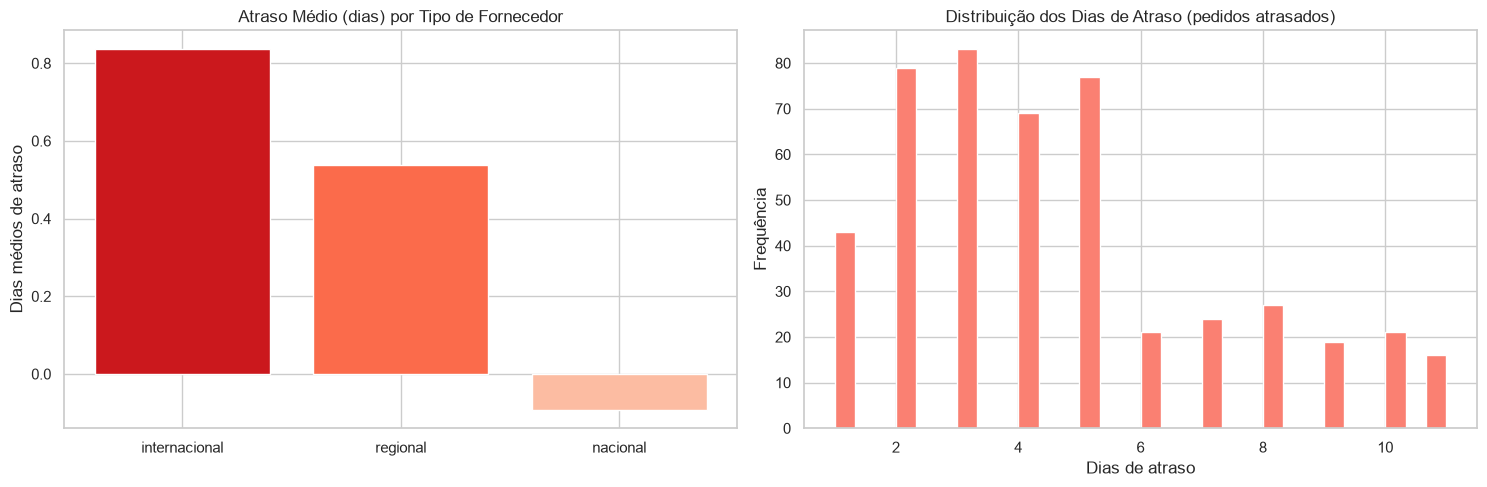

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Atraso médio por tipo de fornecedor
atraso_tipo = df.groupby('tipo_fornecedor')['atraso_dias'].mean().sort_values(ascending=False)
axes[0].bar(atraso_tipo.index, atraso_tipo.values, color=sns.color_palette('Reds_r', len(atraso_tipo)))
axes[0].set_title('Atraso Médio (dias) por Tipo de Fornecedor')
axes[0].set_ylabel('Dias médios de atraso')

# Distribuição dos dias de atraso
atrasados = df[df['atraso_dias'] > 0]['atraso_dias']
axes[1].hist(atrasados, bins=30, color='salmon', edgecolor='white')
axes[1].set_title('Distribuição dos Dias de Atraso (pedidos atrasados)')
axes[1].set_xlabel('Dias de atraso')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

## Análise de Atrasos por Tipo de Fornecedor e Distribuição

---

### Gráfico 1 — Atraso Médio (dias) por Tipo de Fornecedor

| Tipo de Fornecedor | Atraso Médio (dias) | Intensidade |
|--------------------|---------------------|-------------|
| Internacional      | ~0,84 dias          | Alta        |
| Regional           | ~0,54 dias          | Média       |
| Nacional           | ~-0,09 dias         | Desprezível (levemente adiantado) |

**Observações:**
- Fornecedores **internacionais** são os que mais atrasam: o atraso médio é de ~0,84 dia,
  cerca de 1,6x o do fornecedor regional.
- Fornecedores **nacionais** apresentam, em média, atraso **negativo** (-0,09 dia) — ou seja, entregam
  ligeiramente antes do prazo combinado.
- A hierarquia de risco é clara: internacional > regional > nacional.

---

### Gráfico 2 — Distribuição dos Dias de Atraso (pedidos atrasados)

**Observações:**
- Distribuição concentrada: os atrasos vão de **1 a 11 dias**, sem outliers extremos.
- Concentração forte entre **1 e 5 dias de atraso** (351 dos 479 casos, ~73%), com queda abrupta
  a partir do 6º dia.
- Do 6º ao 11º dia (o máximo observado na base), a frequência se mantém baixa e relativamente estável
  (16 a 27 ocorrências por dia).

---

### Conclusões Combinadas

- O problema de atraso é **superficial em duração** — o maior atraso registrado na base é de
  apenas 11 dias, e quase três quartos dos atrasos são de até 5 dias.
- O **fornecedor internacional** é o principal vetor de risco de atraso; ações de mitigação
  (buffer de estoque, antecipação de pedidos) fazem sentido nesse segmento.
- Fornecedores **nacionais** representam o menor risco — em média, antecipam as entregas,
  o que pode ser aproveitado para reduzir o estoque de segurança nesse segmento.

## Taxa de atraso por Fornecedores

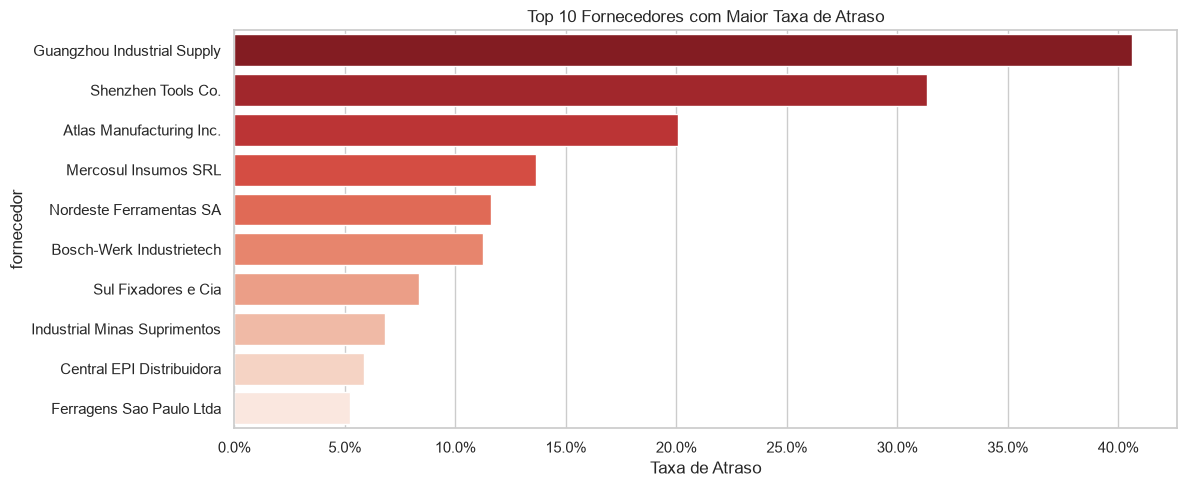

In [11]:
# Top 10 fornecedores com maior taxa de atraso
taxa_atraso_forn = (
    df.groupby('fornecedor')
    .apply(lambda x: (x['atraso_dias'] > 0).mean())
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
taxa_atraso_forn.columns = ['fornecedor', 'taxa_atraso']

plt.figure(figsize=(12, 5))
sns.barplot(data=taxa_atraso_forn, x='taxa_atraso', y='fornecedor', palette='Reds_r')
plt.title('Top 10 Fornecedores com Maior Taxa de Atraso')
plt.xlabel('Taxa de Atraso')
plt.gca().xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.tight_layout()
plt.show()

## Top 10 Fornecedores com Maior Taxa de Atraso

---

### Ranking Completo

| # | Fornecedor                   | Taxa de Atraso (aprox.) | Tipo           |
|---|-------------------------------|--------------------------|----------------|
| 1 | Guangzhou Industrial Supply   | ~40,6%                   | Internacional  |
| 2 | Shenzhen Tools Co.             | ~31,4%                   | Internacional  |
| 3 | Atlas Manufacturing Inc.       | ~20,1%                   | Internacional  |
| 4 | Mercosul Insumos SRL           | ~13,7%                   | Regional       |
| 5 | Nordeste Ferramentas SA        | ~11,6%                   | Nacional       |
| 6 | Bosch-Werk Industrietech       | ~11,3%                   | Internacional  |
| 7 | Sul Fixadores e Cia            | ~8,5%                    | Nacional       |
| 8 | Industrial Minas Suprimentos   | ~6,8%                    | Nacional       |
| 9 | Central EPI Distribuidora      | ~5,8%                    | Nacional       |
| 10| Ferragens São Paulo Ltda.      | ~5,2%                    | Nacional       |

*A base tem exatamente 10 fornecedores cadastrados — o ranking acima cobre, portanto,
a totalidade da carteira.*

*Atenção ao tamanho da amostra: Guangzhou Industrial Supply tem apenas 32 pedidos no período
(13 com atraso), contra 219 a 871 pedidos dos demais fornecedores.*

---

### Observações

**Fornecedores críticos (>15% de atraso):**
- **Guangzhou Industrial Supply** lidera com folga (~40,6%) — cerca de 2 em cada 5 pedidos chegam
  atrasados, o dobro da taxa do terceiro colocado.
- **Shenzhen Tools Co.** (~31,4%) e **Atlas Manufacturing Inc.** (~20,1%) completam o grupo crítico
  — os três são fornecedores internacionais, reforçando o padrão da análise de atraso por tipo.

**Zona de atenção (10%–15%):**
- **Mercosul Insumos SRL** (~13,7%, regional) e **Nordeste Ferramentas SA** (~11,6%, nacional) têm
  taxas relevantes apesar de não serem importados — reforçando que o atraso não é exclusividade internacional.
- **Bosch-Werk Industrietech** (~11,3%, internacional) fecha essa faixa.

**Fornecedores em nível aceitável (<10%):**
- **Sul Fixadores e Cia**, **Industrial Minas Suprimentos**, **Central EPI Distribuidora** e
  **Ferragens São Paulo Ltda.** — todos nacionais — operam abaixo de 10%, com
  **Ferragens São Paulo** apresentando a melhor performance do ranking (~5,2%).

---

### Conclusões

- Os **3 primeiros fornecedores concentram o maior risco logístico** (todos internacionais,
  de 20% a 41% de atraso) e devem ser priorizados em renegociações de prazo, penalidades
  contratuais ou substituição por alternativas nacionais.
- A presença de um fornecedor regional (Mercosul) e um nacional (Nordeste Ferramentas) na zona
  de atenção confirma que o atraso **não é exclusividade de importados**.
- Todos os fornecedores nacionais fora do top 5 operam com taxas baixas (abaixo de 9%),
  reforçando a vantagem logística da proximidade geográfica.
- Recomenda-se revisar com urgência o contrato com **Guangzhou Industrial Supply**, cuja taxa
  de atraso (~40,6%) é a mais alta da carteira.


## 6. Análise de Rupturas de Estoque

Taxa de ruptura geral: 1.6%


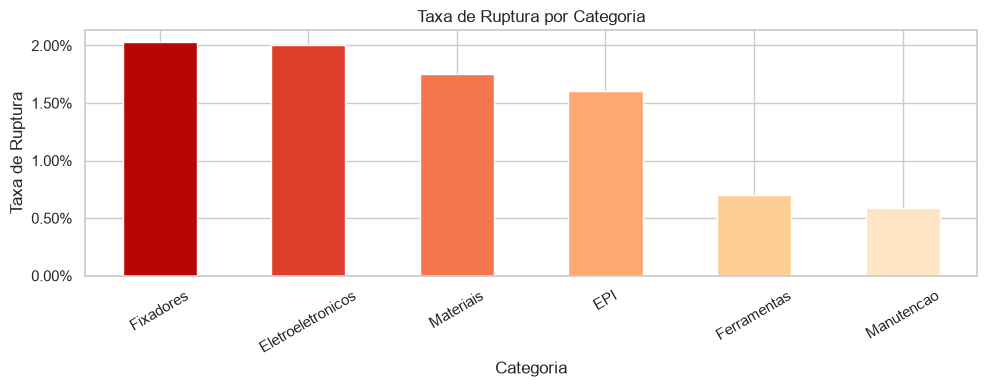

In [12]:
taxa_ruptura_geral = df['ruptura_real'].sum() / df.shape[0] * 100
print(f'Taxa de ruptura geral: {taxa_ruptura_geral:.1f}%')

# Ruptura por categoria
ruptura_cat = df.groupby('categoria')['ruptura_real'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 4))
ruptura_cat.plot(kind='bar', color=sns.color_palette('OrRd_r', len(ruptura_cat)), edgecolor='white')
plt.title('Taxa de Ruptura por Categoria')
plt.ylabel('Taxa de Ruptura')
plt.xlabel('Categoria')
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Análise de Rupturas de Estoque

### Taxa de Ruptura Geral
- **1,6%** dos registros apresentaram ruptura real de estoque.

---

### Taxa de Ruptura por Categoria

| # | Categoria         | Taxa de Ruptura (aprox.) | Nível de Risco |
|---|-------------------|--------------------------|----------------|
| 1 | Fixadores         | ~2,0%                    | Médio          |
| 2 | Eletroeletrônicos | ~2,0%                    | Médio          |
| 3 | Materiais         | ~1,8%                    | Médio          |
| 4 | EPI               | ~1,6%                    | Médio-Baixo    |
| 5 | Ferramentas       | ~0,7%                    | Baixo          |
| 6 | Manutenção        | ~0,6%                    | Baixo          |

---

### Observações

**Distribuição equilibrada entre categorias:**
- A taxa de ruptura varia de 0,6% a 2,0% — nenhuma categoria concentra sozinha o risco.
- Nenhuma categoria apresenta ruptura igual a zero; todas têm alguma exposição.

**Fixadores e Eletroeletrônicos (~2,0% cada):**
- São as categorias com maior taxa de ruptura, ainda que por margem pequena sobre as demais.
- Para Fixadores, isso é especialmente relevante dado o volume de demanda extremamente alto
  identificado na análise de sazonalidade — mesmo uma taxa de ruptura moderada representa um
  volume absoluto de pedidos não atendidos considerável.

**Materiais e EPI (1,6%–1,8%):**
- Próximas da média geral (1,6%), sem indicar risco desproporcional.

**Ferramentas e Manutenção (~0,6%–0,7%):**
- São as categorias com menor risco de ruptura.

---

### Conclusões

- A taxa geral de **1,6%** é baixa e não está concentrada em uma ou duas categorias —
  o risco de ruptura é pulverizado.
- **Fixadores é a categoria prioritária de revisão de estoque mínimo**, pois combina
  o maior volume de demanda absoluto com a maior taxa de ruptura.
- **EPI, a segunda maior categoria em volume, tem risco igual à média geral (1,6%)** —
  a política de estoque de segurança pode ser distribuída de forma equilibrada entre as categorias.

## Evolução da Taxa de Ruptura por Trimestre

Taxa de ruptura por giro do produto:
  alto    : 2.0%
  baixo   : 1.8%
  medio   : 0.8%


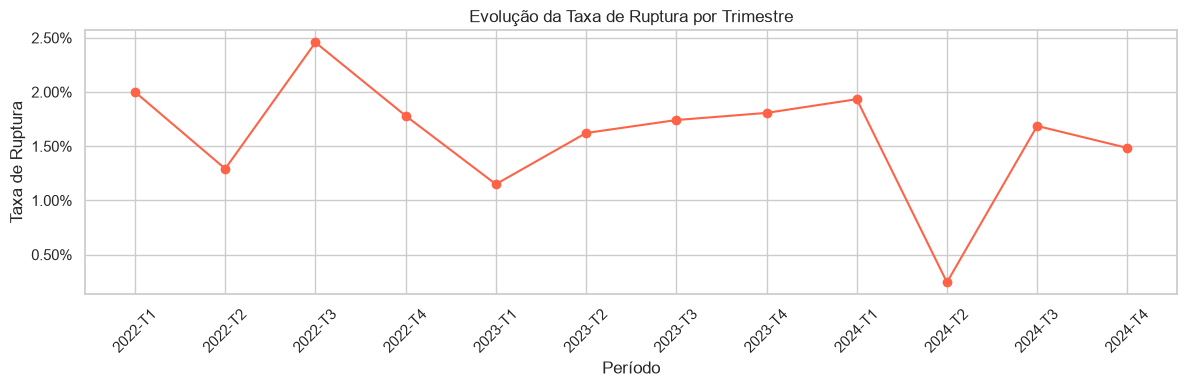

In [13]:
# Ruptura por giro do produto
ruptura_giro = df.groupby('giro_produto')['ruptura_real'].mean().sort_values(ascending=False)
print('Taxa de ruptura por giro do produto:')
for giro, taxa in ruptura_giro.items():
    print(f'  {str(giro):8s}: {taxa*100:.1f}%')

# Evolução das rupturas por trimestre
ruptura_trim = df.groupby(['ano', 'trimestre'])['ruptura_real'].mean().reset_index()
ruptura_trim['periodo'] = ruptura_trim.apply(
    lambda r: f"{int(r['ano'])}-T{int(r['trimestre'])}", axis=1
)

plt.figure(figsize=(12, 4))
plt.plot(ruptura_trim['periodo'], ruptura_trim['ruptura_real'], marker='o', color='tomato')
plt.title('Evolução da Taxa de Ruptura por Trimestre')
plt.ylabel('Taxa de Ruptura')
plt.xlabel('Período')
plt.gca().yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Evolução da Taxa de Ruptura por Trimestre

### Taxa de Ruptura por Giro do Produto

| Giro do Produto | Taxa de Ruptura |
|-----------------|-----------------|
| Alto            | 2,0%            |
| Baixo           | 1,8%            |
| Médio           | 0,8%            |

> Produtos de **giro alto** concentram a maior taxa de ruptura (2,0%), mas a diferença para o
> **giro baixo** (1,8%) é pequena — o giro **médio** é o que apresenta o menor risco (0,8%).

---

### Evolução Trimestral

| Período  | Taxa   | Tendência                       |
|----------|--------|----------------------------------|
| 2022-T1  | 2,0%   | Início moderado                  |
| 2022-T2  | 1,3%   | Queda                             |
| 2022-T3  | 2,5%   | Pico do ano                       |
| 2022-T4  | 1,8%   | Recuo                             |
| 2023-T1  | 1,1%   | Menor valor do ano                |
| 2023-T2  | 1,6%   | Recuperação                       |
| 2023-T3  | 1,7%   | Estável                           |
| 2023-T4  | 1,8%   | Pico do ano                       |
| 2024-T1  | 1,9%   | Pico do ano                       |
| 2024-T2  | 0,2%   | Queda abrupta — menor valor da série |
| 2024-T3  | 1,7%   | Recuperação                       |
| 2024-T4  | 1,5%   | Leve recuo                        |

---

### Observações

**Sem padrão sazonal claro:**
- A série **não apresenta um padrão sazonal consistente**: o trimestre de maior ruptura
  varia a cada ano — T3 em 2022, T4 em 2023 e T1 em 2024.
- As taxas oscilam entre 0,2% e 2,5%, sem uma tendência clara de agravamento ao longo do tempo.

**Ponto de atenção — 2024-T2:**
- Queda abrupta para 0,2%, o menor valor de toda a série — um outlier que vale investigar
  isoladamente (pode refletir uma reposição de estoque pontual ou uma mudança real no
  comportamento de demanda desse trimestre).

---

### Conclusões

- A ruptura de estoque **não é previsivelmente sazonal** — não há um trimestre fixo de
  maior risco ao longo dos três anos.
- Os dados de giro (2,0% para giro alto) apontam que produtos de giro alto merecem atenção
  prioritária, mas a diferença para o giro baixo (1,8%) é pequena o suficiente para não
  tratá-los de forma muito distinta.
- Recomenda-se investigar a queda de 2024-T2 (0,2%) para entender se reflete uma melhoria
  real de processo que pode ser replicada nos demais trimestres.
- Sem um padrão sazonal recorrente, o planejamento de estoque de segurança deve se apoiar
  mais no comportamento por categoria e por giro do produto do que em uma janela fixa do ano.

## 7. Análise de Custos Logísticos

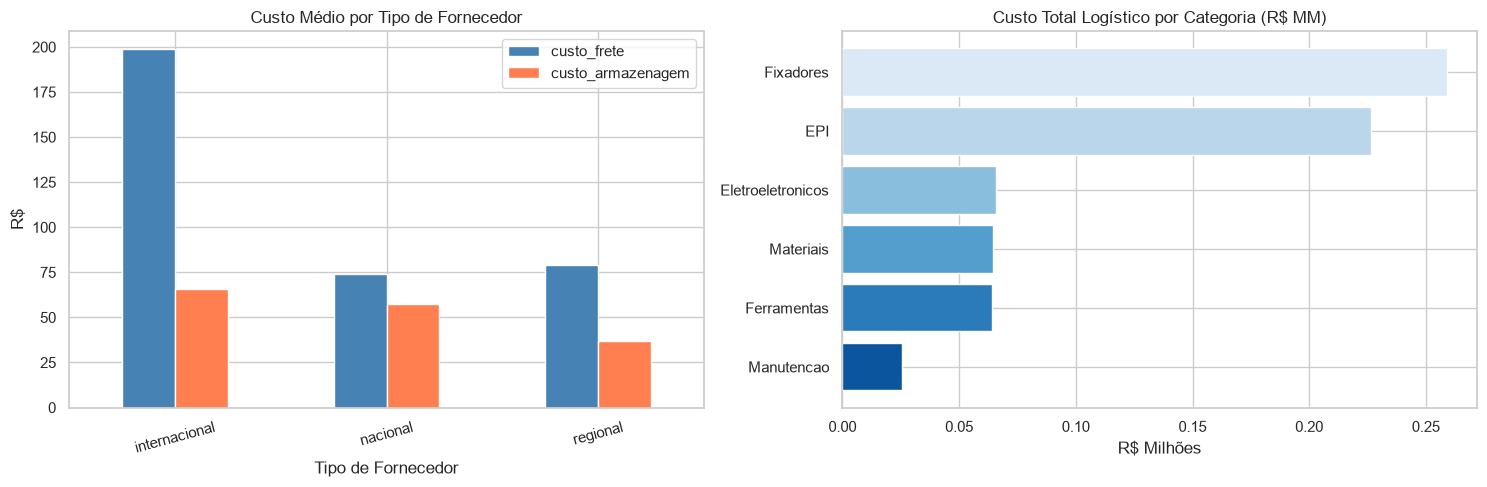

In [14]:
df['custo_total_logistico'] = df['custo_frete'] + df['custo_armazenagem']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Custo médio de frete por tipo de fornecedor
custo_tipo = df.groupby('tipo_fornecedor')[['custo_frete', 'custo_armazenagem']].mean()
custo_tipo.plot(kind='bar', ax=axes[0], color=['steelblue', 'coral'], edgecolor='white')
axes[0].set_title('Custo Médio por Tipo de Fornecedor')
axes[0].set_ylabel('R$')
axes[0].set_xlabel('Tipo de Fornecedor')
axes[0].tick_params(axis='x', rotation=15)

# Custo total logístico por categoria
custo_cat = df.groupby('categoria')['custo_total_logistico'].sum().sort_values(ascending=True)
axes[1].barh(custo_cat.index, custo_cat.values / 1e6, color=sns.color_palette('Blues_r', len(custo_cat)))
axes[1].set_title('Custo Total Logístico por Categoria (R$ MM)')
axes[1].set_xlabel('R$ Milhões')

plt.tight_layout()
plt.show()

## Análise de Custos Logísticos

---

### Gráfico 1 — Custo Médio por Tipo de Fornecedor (R$)

| Tipo de Fornecedor | Custo Frete (aprox.) | Custo Armazenagem (aprox.) | Relação Frete/Armaz. |
|--------------------|----------------------|-----------------------------|-----------------------|
| Internacional      | ~R$ 199              | ~R$ 66                      | ~3,0x                 |
| Regional           | ~R$ 79               | ~R$ 37                      | ~2,1x                 |
| Nacional           | ~R$ 74               | ~R$ 57                      | ~1,3x                 |

**Observações:**
- O **frete internacional** é o maior custo unitário da análise (~R$ 199), cerca de
  **2,7x o frete nacional** e **2,5x o regional** — o principal driver de custo.
- **Nacional e regional têm custos de frete praticamente equivalentes** (~R$ 74 e ~R$ 79).
- No **custo de armazenagem**, o fornecedor **regional** apresenta o menor valor (~R$ 37);
  internacional (~R$ 66) e nacional (~R$ 57) ficam acima dele.

---

### Gráfico 2 — Custo Total Logístico por Categoria (R$ Milhões)

| Categoria         | Custo Total (aprox.) |
|-------------------|------------------------|
| Fixadores         | ~R$ 0,26 MM            |
| EPI               | ~R$ 0,23 MM            |
| Eletroeletrônicos | ~R$ 0,07 MM            |
| Materiais         | ~R$ 0,06 MM            |
| Ferramentas       | ~R$ 0,06 MM            |
| Manutenção        | ~R$ 0,03 MM            |

**Observações:**
- **Fixadores lidera o custo logístico total** (~R$ 0,26 MM), à frente de EPI
  (~R$ 0,23 MM) — consistente com o volume de demanda muito maior identificado na análise
  de sazonalidade.
- **Eletroeletrônicos, Materiais e Ferramentas** ficam próximos entre si (~R$ 0,06–0,07 MM
  cada).
- **Manutenção** é a categoria de menor custo logístico total (~R$ 0,03 MM).

---

### Conclusões Combinadas

- **Fixadores e EPI concentram, juntas, ~69% do custo logístico total** (~R$ 0,49 MM de
  ~R$ 0,71 MM), refletindo o volume de pedidos superior dessas duas categorias.
- O **frete internacional** é o principal driver de custo unitário: 2,7x o frete nacional.
- O **custo de armazenagem regional é o menor entre os três tipos de fornecedor**, o que pode
  refletir a composição de produtos atendida por esse fornecedor.
- Recomenda-se uma análise de **TCO (Custo Total de Propriedade)** por fornecedor, já que
  frete e armazenagem se comportam de forma diferente entre os tipos.

## Matriz de Correlação

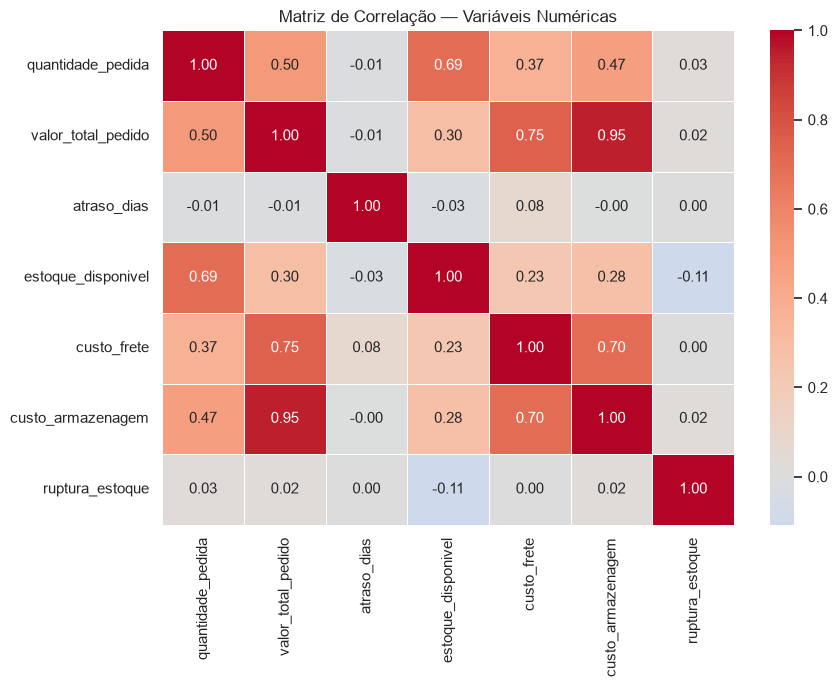

In [15]:
# Correlação entre variáveis numéricas
cols_corr = ['quantidade_pedida', 'valor_total_pedido', 'atraso_dias',
             'estoque_disponivel', 'custo_frete', 'custo_armazenagem',
             'ruptura_estoque']
corr = df[cols_corr].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Matriz de Correlação — Variáveis Numéricas')
plt.tight_layout()
plt.show()

## Matriz de Correlação — Variáveis Numéricas

---

### Correlações Relevantes

#### Fortes (|r| ≥ 0,7) — Vermelho escuro
| Par de Variáveis                            | Correlação | Interpretação                                                                 |
|-----------------------------------------------|------------|-------------------------------------------------------------------------------|
| `valor_total_pedido` × `custo_armazenagem`    | **+0.95**  | O custo de armazenagem é quase inteiramente explicado pelo valor do pedido    |
| `valor_total_pedido` × `custo_frete`          | **+0.75**  | Pedidos de maior valor geram fretes proporcionalmente maiores                 |
| `custo_frete` × `custo_armazenagem`           | **+0.70**  | Os dois componentes de custo logístico andam fortemente juntos                |

#### Moderadas (0,3 ≤ |r| < 0,7) — Vermelho/Azul médio
| Par de Variáveis                            | Correlação | Interpretação                                                              |
|---------------------------------------------|------------|----------------------------------------------------------------------------|
| `quantidade_pedida` × `estoque_disponivel`  | **+0.69**  | Pedidos maiores ocorrem nos itens que mantêm mais estoque disponível       |
| `quantidade_pedida` × `valor_total_pedido`  | **+0.50**  | Mais itens pedidos geram maior valor total (relação esperada)              |
| `quantidade_pedida` × `custo_armazenagem`   | **+0.47**  | Maiores volumes aumentam custos de armazenagem                             |
| `quantidade_pedida` × `custo_frete`         | **+0.37**  | Maiores volumes também elevam o frete, em menor grau                       |
| `valor_total_pedido` × `estoque_disponivel` | **+0.30**  | Pedidos de maior valor tendem a ocorrer onde há mais estoque disponível    |

#### Fracas ou Nulas (|r| < 0,30) — Cinza/Neutro
| Par de Variáveis                        | Correlação        | Interpretação                                                                      |
|-----------------------------------------|--------------------|--------------------------------------------------------------------------------------|
| `atraso_dias` × qualquer outra variável | entre -0.03 e +0.08 | Atraso **sem relação linear relevante** com volume, valor, estoque ou custo        |
| `estoque_disponivel` × `custo_armazenagem` | **+0.28**       | Associação fraca                                                                    |
| `estoque_disponivel` × `custo_frete`    | **+0.23**          | Associação fraca                                                                    |
| `ruptura_estoque` × `estoque_disponivel`| **-0.11**          | Única relação minimamente perceptível da ruptura com as demais variáveis, ainda assim fraca |

---

### Conclusões

- **Relação dominante:** `valor_total_pedido` e `custo_armazenagem` (r = 0,95) — o custo de
  armazenar é quase inteiramente explicado pelo valor financeiro do pedido.
- **Custo logístico escala com o valor do pedido:** `valor_total_pedido` também se correlaciona
  fortemente com `custo_frete` (r = 0,75) — pedidos mais valiosos são mais caros de transportar,
  não apenas de armazenar.
- **Estoque acompanha o volume:** `estoque_disponivel` tem correlação positiva com
  `quantidade_pedida` (0,69) e com `valor_total_pedido` (0,30) — os itens mais pedidos são
  os que mantêm os maiores estoques.
- **Atraso é a variável mais independente** do conjunto — suas causas são
  qualitativas (tipo de fornecedor), não quantitativas.
- A **ruptura de estoque** praticamente não tem correlação linear mensurável com as demais
  variáveis contínuas, reforçando que é um evento determinado por fatores categóricos
  (categoria, giro do produto).

## 8. Análise Geográfica — Estados com Maior Volume

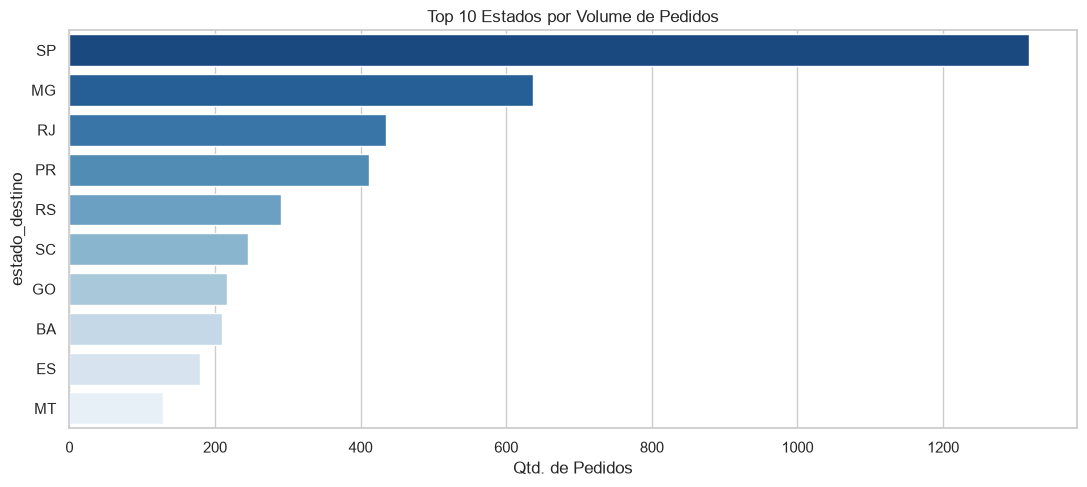

In [16]:
# Top 10 estados por volume de pedidos
top_estados = df['estado_destino'].value_counts().head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=top_estados.values, y=top_estados.index, palette='Blues_r')
plt.title('Top 10 Estados por Volume de Pedidos')
plt.xlabel('Qtd. de Pedidos')
plt.tight_layout()
plt.show()

## 9. Resumo dos Principais Insights

| # | Insight | Impacto |
|---|---|---|
| 1 | Fornecedores internacionais concentram a maior parte dos atrasos (top 3 do ranking, 20–41%) | Alto |
| 2 | Fixadores e Eletroeletrônicos têm as maiores taxas de ruptura (~2,0%), com o risco distribuído entre as categorias (0,6% a 2,0%) | Médio |
| 3 | Demanda de EPI tem picos em Maio e Outubro e vale em Dezembro | Médio |
| 4 | Sudeste concentra ~58% dos pedidos (SP, MG e RJ somam ~54%) | Informativo |
| 5 | Produtos de giro baixo têm taxa de ruptura próxima à de giro alto — desproporcional ao volume que movimentam | Médio |

> **Próxima etapa:** Limpeza e criação de features derivadas para modelagem.
